/home/nkb/papp/.venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/nkb/papp/.venv/lib/python3.13/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/home/nkb/papp/.venv/lib/python3.13/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
findfont: Failed to find font weight medium for DejaVu San

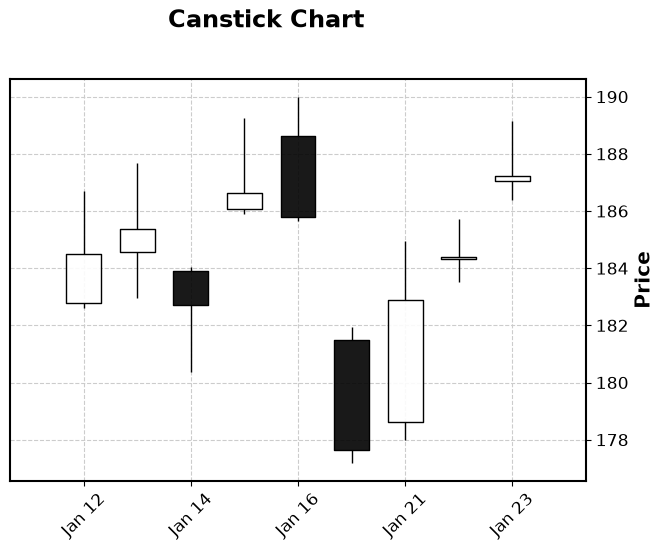

In [1]:
import yfinance as yf
import pandas as pd
import mplfinance as mpl

ticker = "NVDA"
data = yf.Ticker(ticker).history(start="2026-01-10",end="2026-01-25")
df = pd.DataFrame(data)
mpl.plot(df,type='candle',style='classic',title='Canstick Chart')

In [2]:
s = pd.Series(range(5))
t=s.rolling(window=3,min_periods=3).sum()
t


0    NaN
1    NaN
2    3.0
3    6.0
4    9.0
dtype: float64

In [3]:
for window in s.rolling(window=3):
    print(window)

0    0
dtype: int64
0    0
1    1
dtype: int64
0    0
1    1
2    2
dtype: int64
1    1
2    2
3    3
dtype: int64
2    2
3    3
4    4
dtype: int64


In [4]:
df = pd.DataFrame(range(5))
# t=df.rolling(window=len(df),min_periods=1).mean()
t=df.expanding(min_periods=1).mean()
t

,0
0,0.0
1,0.5
2,1.0
3,1.5
4,2.0


In [5]:
t=df.ewm(alpha=0.8,adjust=False).mean()
t

,0
0,0.0000
1,0.8000
2,1.7600
3,2.7520
4,3.7504


In [6]:
import pandas as pd

close = pd.Series([100, 102, 104, 103, 106, 109])
sma_3= close.rolling(window=3,min_periods=1).mean()

result = pd.DataFrame({
    "close":close,
    "sma_3":sma_3
})
# result=result.rolling(window=3).mean()
print(result.round(2))

   close   sma_3
0    100  100.00
1    102  101.00
2    104  102.00
3    103  103.00
4    106  104.33
5    109  106.00


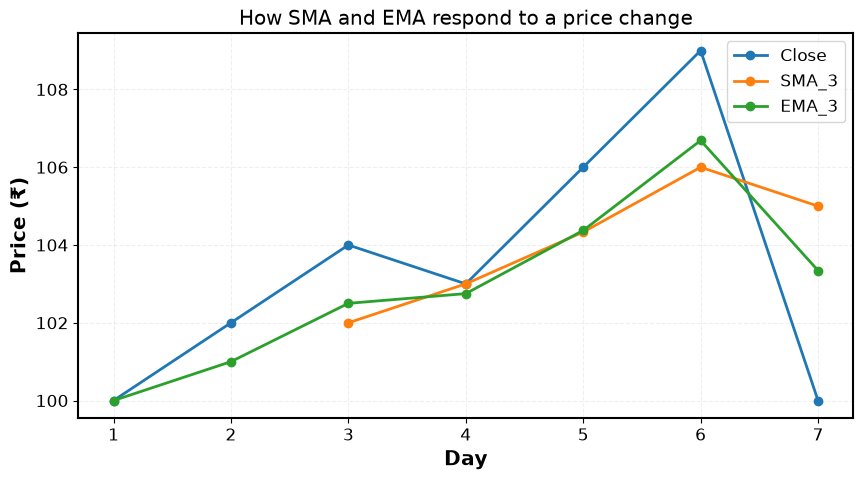

   Close   SMA_3   EMA_3  Distance_from_SMA  SMA_change
1    100     NaN  100.00                NaN         NaN
2    102     NaN  101.00                NaN         NaN
3    104  102.00  102.50               2.00         NaN
4    103  103.00  102.75               0.00        1.00
5    106  104.33  104.38               1.67        1.33
6    109  106.00  106.69               3.00        1.67
7    100  105.00  103.34              -5.00       -1.00


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Close":[100,102,104,103,106,109,100]})
df.index = range(1,len(df)+1)
df["SMA_3"] = df["Close"].rolling(window=3).mean()

df["EMA_3"] = df["Close"].ewm(span=3, adjust=False).mean()

# df["SMA_5"] = df["Close"].rolling(window=5).mean()
# df["EMA_5"] = df["Close"].ewm(span=5, adjust=False).mean()
# Plot each column as a separate line
df.plot(marker="o", figsize=(10, 5))

plt.title("How SMA and EMA respond to a price change")
plt.xlabel("Day")
plt.ylabel("Price (₹)")
plt.grid(alpha=0.3)
plt.show()

# Positive: price is above the SMA
# Negative: price is below the SMA
df["Distance_from_SMA"] = df["Close"] - df["SMA_3"]

# Current SMA minus the previous row's SMA
df["SMA_change"] = df["SMA_3"].diff()
print(df.round(2))

     Close   SMA_3  SMA_5  Bullish_cross  Bearish_cross   Signal
Day                                                             
1      100     NaN    NaN          False          False         
2      102     NaN    NaN          False          False         
3      104  102.00    NaN          False          False         
4      103  103.00    NaN          False          False         
5      106  104.33  103.0          False          False         
6      109  106.00  104.8          False          False         
7      100  105.00  104.4          False          False         
8       96  101.67  102.8          False           True  Bearish
9       94   96.67  101.0          False          False         
10      98   96.00   99.4          False          False         
11     102   98.00   98.0          False          False         
12     106  102.00   99.2           True          False  Bullish
13     110  106.00  102.0          False          False         


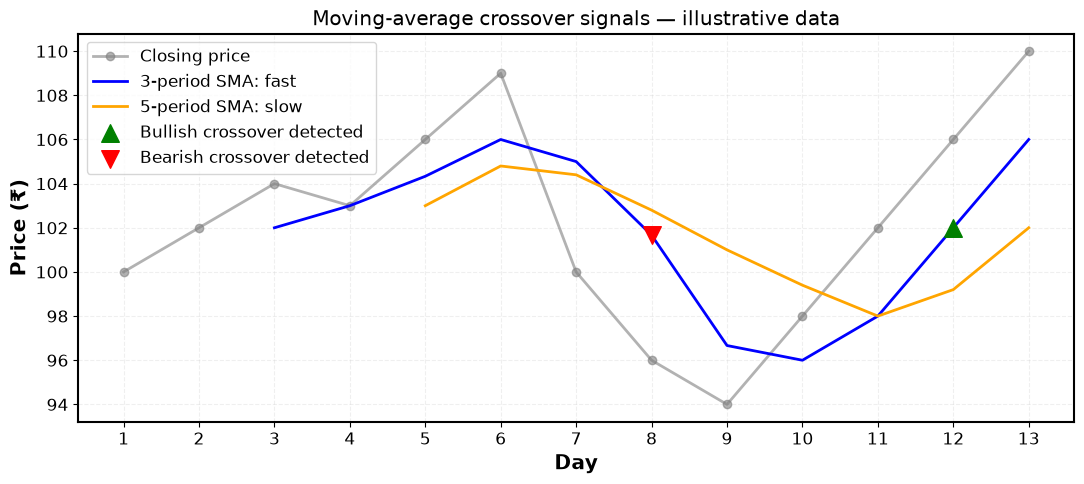

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Illustrative prices—not real market data
df = pd.DataFrame({
    "Close": [
        100, 102, 104, 103, 106, 109, 100,  # Your original data
        96, 94, 98, 102, 106, 110           # Additional observations
    ]
})

df.index = range(1, len(df) + 1)
df.index.name = "Day"

# 1. Calculate the moving averages
df["SMA_3"] = df["Close"].rolling(window=3).mean()
df["SMA_5"] = df["Close"].rolling(window=5).mean()

fast = df["SMA_3"]
slow = df["SMA_5"]

# 2. Detect changes in their relationship
df["Bullish_cross"] = (
    (fast > slow)
    & (fast.shift(1) <= slow.shift(1))
)

df["Bearish_cross"] = (
    (fast < slow)
    & (fast.shift(1) >= slow.shift(1))
)

# 3. Add a readable signal label
df["Signal"] = ""
df.loc[df["Bullish_cross"], "Signal"] = "Bullish"
df.loc[df["Bearish_cross"], "Signal"] = "Bearish"

# Display every row
print(df.round(2).to_string())

# 4. Select only the rows where a signal occurred
bullish = df.loc[df["Bullish_cross"]]
bearish = df.loc[df["Bearish_cross"]]

# 5. Plot prices and both averages
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    df.index, df["Close"],
    color="gray", marker="o", alpha=0.6, label="Closing price"
)
ax.plot(
    df.index, df["SMA_3"],
    color="blue", linewidth=2, label="3-period SMA: fast"
)
ax.plot(
    df.index, df["SMA_5"],
    color="orange", linewidth=2, label="5-period SMA: slow"
)

# Mark the fast SMA on the day each signal is detected
ax.scatter(
    bullish.index, bullish["SMA_3"],
    marker="^", color="green", s=160,
    label="Bullish crossover detected", zorder=5
)
ax.scatter(
    bearish.index, bearish["SMA_3"],
    marker="v", color="red", s=160,
    label="Bearish crossover detected", zorder=5
)

ax.set_title("Moving-average crossover signals — illustrative data")
ax.set_xlabel("Day")
ax.set_ylabel("Price (₹)")
ax.set_xticks(df.index)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

##### Bollinger Bands

In [10]:
import pandas as pd

a = pd.Series([99, 100, 101])
b = pd.Series([199, 200, 201])

print(a.std(ddof=0))  # 0.816496...
print(b.std(ddof=0))  # 0.816496...

print(a.std())  # 0.816496...
print(b.std())  # 0.816496...

0.816496580927726
0.816496580927726
1.0
1.0



Last 10 observations:
     Close  Middle  StdDev   Upper   Lower
Day                                       
31     116  109.10    3.79  116.69  101.51
32     119  109.75    4.29  118.33  101.17
33     117  110.15    4.56  119.28  101.02
34     115  110.40    4.68  119.77  101.03
35     112  110.60    4.66  119.93  101.27
36     109  110.50    4.67  119.85  101.15
37     111  110.45    4.66  119.78  101.12
38     114  110.65    4.73  120.10  101.20
39     118  110.90    4.97  120.84  100.96
40     122  111.30    5.50  122.29  100.31

Calculation for day 40:
Closing price:      122.00
20-period average:  111.30
Standard deviation: 5.50
Upper band = 111.30 + 2 × 5.50 = 122.29
Lower band = 111.30 - 2 × 5.50 = 100.31


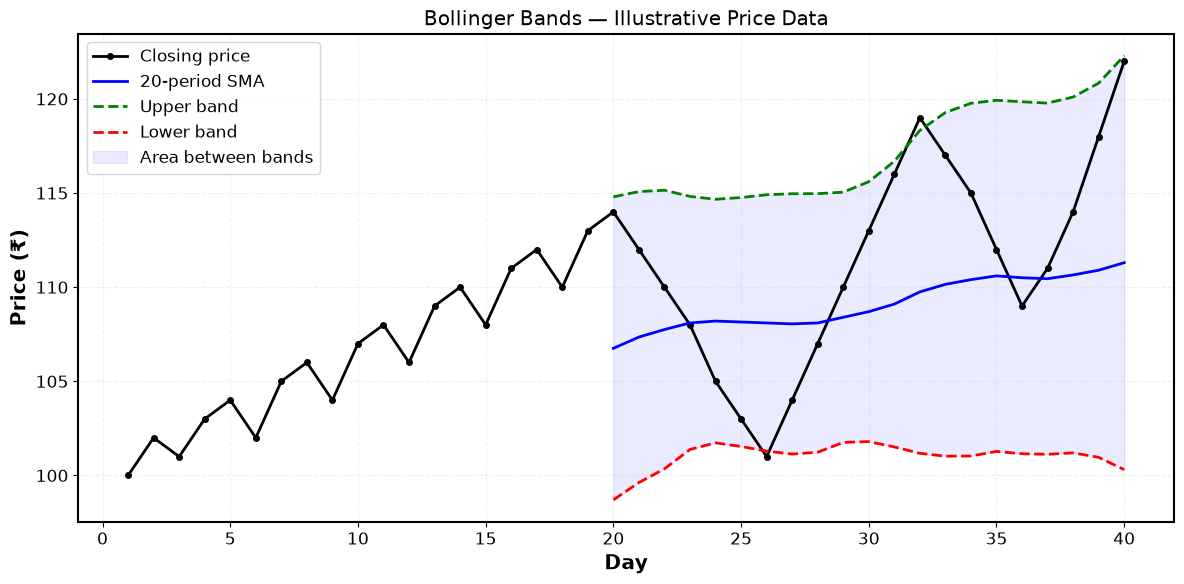

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Create illustrative daily closing prices
prices = [
    100, 102, 101, 103, 104, 102, 105, 106, 104, 107,
    108, 106, 109, 110, 108, 111, 112, 110, 113, 114,
    112, 110, 108, 105, 103, 101, 104, 107, 110, 113,
    116, 119, 117, 115, 112, 109, 111, 114, 118, 122
]

df = pd.DataFrame({"Close": prices})
df.index = range(1, len(df) + 1)
df.index.name = "Day"

# 2. Choose the Bollinger Band settings
window = 20       # Number of closing prices in each window
multiplier = 2    # Band distance in standard deviations

# 3. Calculate the middle band: simple moving average
df["Middle"] = df["Close"].rolling(window=window).mean()

# 4. Calculate the standard deviation within each window
# ddof=0 divides by the number of observations
df["StdDev"] = df["Close"].rolling(window=window).std(ddof=0)

# 5. Calculate the upper and lower bands
df["Upper"] = df["Middle"] + multiplier * df["StdDev"]
df["Lower"] = df["Middle"] - multiplier * df["StdDev"]

# 6. Display the last 10 rows
print("\nLast 10 observations:")
print(df.tail(10).round(2).to_string())

# 7. Explain the latest calculation numerically
latest = df.iloc[-1]

print(f"\nCalculation for day {df.index[-1]}:")
print(f"Closing price:      {latest['Close']:.2f}")
print(f"20-period average:  {latest['Middle']:.2f}")
print(f"Standard deviation: {latest['StdDev']:.2f}")

print(
    f"Upper band = {latest['Middle']:.2f}"
    f" + {multiplier} × {latest['StdDev']:.2f}"
    f" = {latest['Upper']:.2f}"
)

print(
    f"Lower band = {latest['Middle']:.2f}"
    f" - {multiplier} × {latest['StdDev']:.2f}"
    f" = {latest['Lower']:.2f}"
)

# 8. Plot the closing price and all three bands
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    df.index, df["Close"],
    color="black", marker="o", markersize=4,
    label="Closing price"
)

ax.plot(
    df.index, df["Middle"],
    color="blue", linewidth=2,
    label=f"{window}-period SMA"
)

ax.plot(
    df.index, df["Upper"],
    color="green", linestyle="--",
    label="Upper band"
)

ax.plot(
    df.index, df["Lower"],
    color="red", linestyle="--",
    label="Lower band"
)

# Shade the area between the bands where calculations are available
valid = df.dropna(subset=["Upper", "Lower"])

ax.fill_between(
    valid.index.to_numpy(),
    valid["Lower"].to_numpy(),
    valid["Upper"].to_numpy(),
    color="blue", alpha=0.08,
    label="Area between bands"
)

ax.set_title("Bollinger Bands — Illustrative Price Data")
ax.set_xlabel("Day")
ax.set_ylabel("Price (₹)")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


BTC-USD: last 10 observations
               Close    Middle   StdDev     Upper     Lower  Band_width  Band_width_pct
Date                                                                                   
2026-10-19  81853.54  83244.91  1554.08  86353.08  80136.75     6216.33            7.47
2026-10-20  82941.00  83214.27  1553.73  86321.73  80106.81     6214.92            7.47
2026-10-21  84011.97  83172.21  1519.82  86211.84  80132.58     6079.26            7.31
2026-10-22  81311.89  83012.95  1539.39  86091.73  79934.16     6157.57            7.42
2026-10-23  81074.19  82828.48  1539.61  85907.70  79749.25     6158.45            7.44
2026-10-24  80790.84  82544.00  1352.88  85249.77  79838.24     5411.53            6.56
2026-10-25  80024.01  82255.87  1240.59  84737.06  79774.69     4962.37            6.03
2026-10-26  80006.66  81978.33  1081.63  84141.59  79815.06     4326.53            5.28
2026-10-27  80805.08  81854.79  1067.38  83989.55  79720.02     4269.52            5.22
2

/home/nkb/papp/.venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/nkb/papp/.venv/lib/python3.13/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/home/nkb/papp/.venv/lib/python3.13/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
/home/nkb/papp/.venv/lib/python3.13/site-packages/yfinance

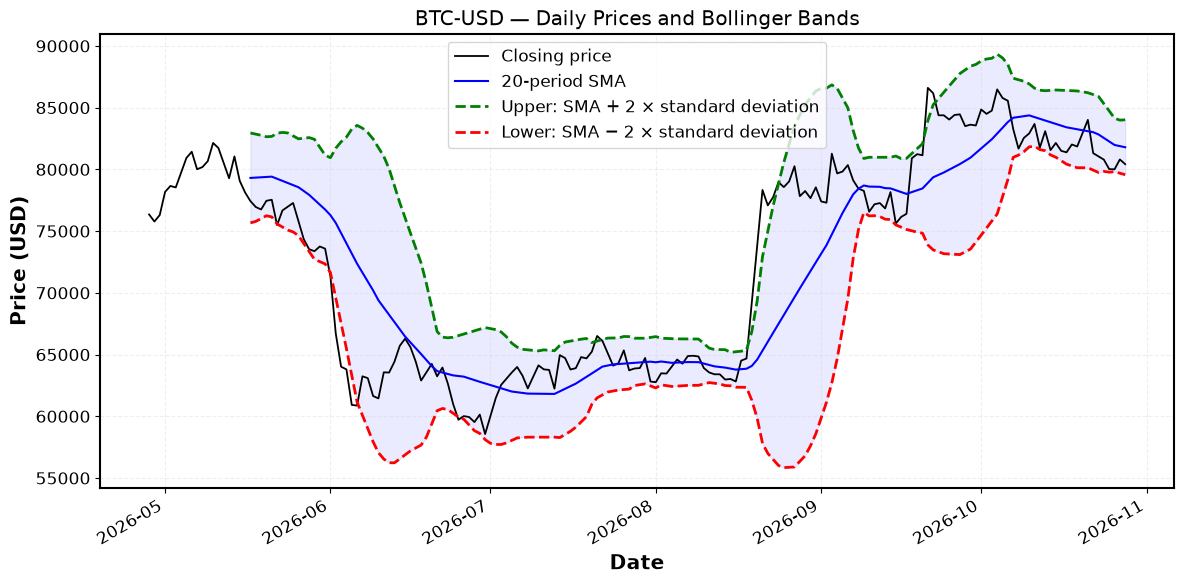

In [13]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# 1. Settings
ticker = "BTC-USD"
period = "6mo"
window = 20
multiplier = 2

# 2. Download daily prices
data = yf.download(
    ticker,
    period=period,
    interval="1d",
    auto_adjust=True,
    multi_level_index=False,
    progress=False
)

# Stop with a clear message if the download failed
if data is None or data.empty:
    raise RuntimeError(
        "No data downloaded. Check your internet connection "
        "and ticker, or try again later."
    )

# 3. Keep closing prices, remove missing values, and sort by date
df = data[["Close"]].dropna().sort_index().copy()

if len(df) < window:
    raise ValueError(
        f"Need at least {window} observations; received {len(df)}."
    )

# 4. Calculate Bollinger Bands
df["Middle"] = df["Close"].rolling(window=window).mean()

df["StdDev"] = (
    df["Close"]
    .rolling(window=window)
    .std(ddof=0)
)

df["Upper"] = df["Middle"] + multiplier * df["StdDev"]
df["Lower"] = df["Middle"] - multiplier * df["StdDev"]
df["Band_width"] = df["Upper"] - df["Lower"]
df["Band_width_pct"] = (
    (df["Upper"] - df["Lower"]) / df["Middle"]
) * 100
# 5. Print the latest calculations
print(f"\n{ticker}: last 10 observations")
print(df.tail(10).round(2).to_string())

latest = df.iloc[-1]

print(f"\nLatest observation: {df.index[-1].date()}")
print(f"Closing price:      ${latest['Close']:,.2f}")
print(f"Middle band:        ${latest['Middle']:,.2f}")
print(f"Standard deviation: ${latest['StdDev']:,.2f}")
print(f"Upper band:         ${latest['Upper']:,.2f}")
print(f"Lower band:         ${latest['Lower']:,.2f}")

# 6. Plot price and bands
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    df.index, df["Close"],
    color="black", linewidth=1.3,
    label="Closing price"
)

ax.plot(
    df.index, df["Middle"],
    color="blue", linewidth=1.5,
    label=f"{window}-period SMA"
)

ax.plot(
    df.index, df["Upper"],
    color="green", linestyle="--",
    label=f"Upper: SMA + {multiplier} × standard deviation"
)

ax.plot(
    df.index, df["Lower"],
    color="red", linestyle="--",
    label=f"Lower: SMA − {multiplier} × standard deviation"
)

# Shade only the dates where both bands are available
valid = df.dropna(subset=["Upper", "Lower"])

ax.fill_between(
    valid.index,
    valid["Lower"].to_numpy(),
    valid["Upper"].to_numpy(),
    color="blue",
    alpha=0.08
)

ax.set_title(f"{ticker} — Daily Prices and Bollinger Bands")
ax.set_xlabel("Date")
ax.set_ylabel("Price (USD)")
ax.grid(alpha=0.3)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [18]:
df["EMA_12"] = df["Close"].ewm(span=12, adjust=False).mean()
df["EMA_26"] = df["Close"].ewm(span=26, adjust=False).mean()

df["MACD"] = df["EMA_12"] - df["EMA_26"]

print(df[["Close", "EMA_12", "EMA_26", "MACD"]].tail())
df["Signal"] = df["MACD"].ewm(span=9, adjust=False).mean()
df["Histogram"] = df["MACD"] - df["Signal"]


                   Close        EMA_12        EMA_26        MACD
Date                                                            
2026-10-24  80790.835938  82020.976713  82201.161902 -180.185189
2026-10-25  80024.007812  81713.750729  82039.891229 -326.140500
2026-10-26  80006.656250  81451.120809  81889.281230 -438.160421
2026-10-27  80805.078125  81351.729627  81808.969889 -457.240262
2026-10-28  80422.953125  81208.840934  81706.301981 -497.461047
